# Multi-objective optimization of pharmaceutical tablet production

This notebook refactors a technical case study. It identifies historical production profiles that balance two competing objectives:

1. **Minimize tablet friability** — lower material loss and better quality.
2. **Minimize compression force** — lower mechanical demand while preserving quality.

> The NSGA-II search recovers the complete exact Pareto front. The strongest observed profile reaches **0.25% friability at 24.55 kN**.

## 1. Objective

What we are looking for:

- keeps all records from the same production lot in the same validation fold;
- computes the mathematically exact Pareto front as a ground-truth benchmark;
- uses `ParetoFront` rather than a scalar-style hall of fame;
- validates the evolutionary search by measuring Pareto coverage;
- separates historical evidence from causal or production-ready claims.

In [ ]:
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "deap": "deap>=1.4.2",
    "matplotlib": "matplotlib>=3.9",
    "numpy": "numpy>=2.0",
    "pandas": "pandas>=2.2",
    "sklearn": "scikit-learn>=1.5",
    "seaborn": "seaborn>=0.13.2",
}

missing_packages = [
    package_spec
    for module_name, package_spec in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(module_name) is None
]

if missing_packages:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing_packages]
    )

Scientific dependencies are available.


In [2]:
from pathlib import Path
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd()


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

NAVY = "#17324D"
TEAL = "#0F766E"
GOLD = "#D97706"
CORAL = "#C2410C"
SLATE = "#64748B"

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.18,
    "legend.frameon": False,
})

In [3]:
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd


COLUMN_MAP = {
    "Unnamed: 0": "row_id",
    "indice_lote": "lot_id",
    "PreC_VM": "precompression_kn",
    "CP_VM": "compression_kn",
    "Peso_VM": "mean_weight_mg",
    "Peso_min": "min_weight_mg",
    "Peso_max": "max_weight_mg",
    "Diametro_VM": "thickness_mm",
    "Dureza_VM": "hardness_kp",
    "Diametro_VM.1": "diameter_mm",
    "friab": "friability_fraction",
}

FEATURE_COLUMNS = [
    "precompression_kn",
    "compression_kn",
    "mean_weight_mg",
    "min_weight_mg",
    "max_weight_mg",
    "thickness_mm",
    "hardness_kp",
    "diameter_mm",
]

DISPLAY_NAMES = {
    "precompression_kn": "Precompression",
    "compression_kn": "Compression",
    "mean_weight_mg": "Mean weight",
    "min_weight_mg": "Minimum weight",
    "max_weight_mg": "Maximum weight",
    "thickness_mm": "Thickness",
    "hardness_kp": "Hardness",
    "diameter_mm": "Diameter",
}


def load_production_data(path: str | Path) -> pd.DataFrame:
    data_path = Path(path)
    if not data_path.exists():
        raise FileNotFoundError(
            f"Dataset not found at {data_path}. See data/README.md for setup."
        )

    raw_data = pd.read_csv(data_path)
    missing_columns = sorted(set(COLUMN_MAP) - set(raw_data.columns))
    if missing_columns:
        raise ValueError(f"Dataset is missing required columns: {missing_columns}")

    data = raw_data.rename(columns=COLUMN_MAP)[list(COLUMN_MAP.values())].copy()
    numeric_columns = ["row_id", "lot_id", *FEATURE_COLUMNS, "friability_fraction"]
    data[numeric_columns] = data[numeric_columns].apply(pd.to_numeric, errors="raise")

    if data[numeric_columns].isna().any().any():
        missing = data[numeric_columns].isna().sum()
        raise ValueError(f"Missing values detected: {missing[missing.gt(0)].to_dict()}")
    if not np.isfinite(data[numeric_columns].to_numpy(dtype=float)).all():
        raise ValueError("Infinite values detected in numeric columns.")
    if not data["friability_fraction"].between(0, 1).all():
        raise ValueError("Friability must be expressed as a fraction between 0 and 1.")
    if data["compression_kn"].le(0).any():
        raise ValueError("Compression pressure must be positive.")

    data["row_id"] = data["row_id"].astype(int)
    data["lot_id"] = data["lot_id"].astype(int)
    data["friability_pct"] = data["friability_fraction"] * 100
    return data.sort_values("row_id").reset_index(drop=True)


def summarize_data_quality(data: pd.DataFrame) -> dict[str, int | float | bool]:
    compression = data["compression_kn"]
    first_quartile = float(compression.quantile(0.25))
    third_quartile = float(compression.quantile(0.75))
    lower_fence = first_quartile - 1.5 * (third_quartile - first_quartile)

    return {
        "rows": int(len(data)),
        "lots": int(data["lot_id"].nunique()),
        "missing_values": int(data.isna().sum().sum()),
        "duplicate_rows": int(data.duplicated().sum()),
        "friability_constant_within_lot": bool(
            data.groupby("lot_id")["friability_pct"].nunique().eq(1).all()
        ),
        "compression_lower_fence_kn": round(lower_fence, 3),
        "compression_low_outliers": int(compression.lt(lower_fence).sum()),
    }

In [4]:
from __future__ import annotations

from collections.abc import Sequence

import numpy as np
import pandas as pd


def non_dominated_mask(values: np.ndarray) -> np.ndarray:
    objective_values = np.asarray(values, dtype=float)
    if objective_values.ndim != 2:
        raise ValueError("Objective values must be a two-dimensional array.")

    mask = np.ones(len(objective_values), dtype=bool)
    for candidate_index, candidate in enumerate(objective_values):
        dominates_candidate = np.all(objective_values <= candidate, axis=1) & np.any(
            objective_values < candidate, axis=1
        )
        dominates_candidate[candidate_index] = False
        if dominates_candidate.any():
            mask[candidate_index] = False
    return mask


def exact_pareto_front(
    data: pd.DataFrame,
    objectives: Sequence[str] = ("friability_pct", "compression_kn"),
) -> pd.DataFrame:
    objective_columns = list(objectives)
    missing_columns = sorted(set(objective_columns) - set(data.columns))
    if missing_columns:
        raise ValueError(f"Missing objective columns: {missing_columns}")

    candidates = (
        data.sort_values([*objective_columns, "row_id"])
        .drop_duplicates(objective_columns, keep="first")
        .reset_index(drop=True)
    )
    mask = non_dominated_mask(candidates[objective_columns].to_numpy(dtype=float))
    return candidates.loc[mask].sort_values(objective_columns).reset_index(drop=True)


def pareto_coverage(
    discovered: pd.DataFrame,
    reference: pd.DataFrame,
    objectives: Sequence[str] = ("friability_pct", "compression_kn"),
    tolerance: float = 1e-9,
) -> float:
    if reference.empty:
        return 1.0
    if discovered.empty:
        return 0.0

    discovered_values = discovered[list(objectives)].to_numpy(dtype=float)
    matched = 0
    for reference_value in reference[list(objectives)].to_numpy(dtype=float):
        close = np.all(
            np.isclose(discovered_values, reference_value, atol=tolerance, rtol=0),
            axis=1,
        )
        matched += int(close.any())
    return matched / len(reference)

In [5]:
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold



@dataclass(frozen=True)
class ValidationResult:
    grouped_metrics: pd.DataFrame
    random_row_metrics: pd.DataFrame
    feature_importance: pd.DataFrame

    @property
    def summary(self) -> dict[str, float]:
        return {
            "grouped_r2_mean": float(self.grouped_metrics["r2"].mean()),
            "grouped_r2_std": float(self.grouped_metrics["r2"].std(ddof=0)),
            "grouped_mae_mean": float(self.grouped_metrics["mae"].mean()),
            "random_row_r2_mean": float(self.random_row_metrics["r2"].mean()),
            "random_row_r2_std": float(
                self.random_row_metrics["r2"].std(ddof=0)
            ),
            "random_row_mae_mean": float(
                self.random_row_metrics["mae"].mean()
            ),
        }


def _new_estimator(random_state: int) -> ExtraTreesRegressor:
    return ExtraTreesRegressor(
        n_estimators=500,
        min_samples_leaf=3,
        random_state=random_state,
        n_jobs=1,
    )


def _metric_row(fold: int, truth: pd.Series, prediction: np.ndarray) -> dict[str, float]:
    return {
        "fold": fold,
        "r2": float(r2_score(truth, prediction)),
        "mae": float(mean_absolute_error(truth, prediction)),
        "rmse": float(np.sqrt(mean_squared_error(truth, prediction))),
    }


def evaluate_model_validation(
    data: pd.DataFrame,
    random_state: int = 42,
) -> ValidationResult:
    features = data[FEATURE_COLUMNS]
    target = data["friability_pct"]
    groups = data["lot_id"]
    base_estimator = _new_estimator(random_state)

    grouped_rows: list[dict[str, float]] = []
    permutation_rows: list[pd.Series] = []
    grouped_splitter = GroupKFold(n_splits=5)
    for fold, (train_index, test_index) in enumerate(
        grouped_splitter.split(features, target, groups), start=1
    ):
        estimator = clone(base_estimator)
        estimator.fit(features.iloc[train_index], target.iloc[train_index])
        prediction = estimator.predict(features.iloc[test_index])
        grouped_rows.append(_metric_row(fold, target.iloc[test_index], prediction))

        importance = permutation_importance(
            estimator,
            features.iloc[test_index],
            target.iloc[test_index],
            scoring="r2",
            n_repeats=10,
            random_state=random_state + fold,
            n_jobs=1,
        )
        permutation_rows.append(
            pd.Series(importance.importances_mean, index=FEATURE_COLUMNS, name=fold)
        )

    random_rows: list[dict[str, float]] = []
    random_splitter = KFold(n_splits=5, shuffle=True, random_state=random_state)
    for fold, (train_index, test_index) in enumerate(
        random_splitter.split(features, target), start=1
    ):
        estimator = clone(base_estimator)
        estimator.fit(features.iloc[train_index], target.iloc[train_index])
        prediction = estimator.predict(features.iloc[test_index])
        random_rows.append(_metric_row(fold, target.iloc[test_index], prediction))

    importance_frame = pd.DataFrame(permutation_rows)
    feature_importance = pd.DataFrame(
        {
            "feature": FEATURE_COLUMNS,
            "importance_mean": importance_frame.mean(axis=0).to_numpy(),
            "importance_std": importance_frame.std(axis=0, ddof=0).to_numpy(),
        }
    ).sort_values("importance_mean", ascending=False, ignore_index=True)

    return ValidationResult(
        grouped_metrics=pd.DataFrame(grouped_rows),
        random_row_metrics=pd.DataFrame(random_rows),
        feature_importance=feature_importance,
    )

In [6]:
from __future__ import annotations

import random
from dataclasses import dataclass
from typing import Iterable

import numpy as np
import pandas as pd
from deap import algorithms, base, creator, tools



if not hasattr(creator, "TabletFitnessMin"):
    creator.create("TabletFitnessMin", base.Fitness, weights=(-1.0, -1.0))
if not hasattr(creator, "TabletCandidate"):
    creator.create("TabletCandidate", list, fitness=creator.TabletFitnessMin)


@dataclass(frozen=True)
class NSGA2Result:
    front: pd.DataFrame
    unique_candidates_evaluated: int
    total_evaluations: int
    seeds: tuple[int, ...]


def run_nsga2_search(
    data: pd.DataFrame,
    seeds: Iterable[int] = (7, 19, 42),
    population_size: int = 120,
    offspring_size: int = 240,
    generations: int = 60,
) -> NSGA2Result:
    seed_values = tuple(seeds)
    if not seed_values:
        raise ValueError("At least one random seed is required.")

    profiles = data[FEATURE_COLUMNS].to_numpy(dtype=float)
    profile_std = profiles.std(axis=0)
    profile_std[profile_std == 0] = 1.0
    standardized_profiles = (profiles - profiles.mean(axis=0)) / profile_std
    evaluated_indices: set[int] = set()
    archive_indices: set[int] = set()
    total_evaluations = 0

    def nearest_candidate(profile: np.ndarray) -> int:
        distances = np.square(standardized_profiles - profile).sum(axis=1)
        return int(np.argmin(distances))

    for seed in seed_values:
        random.seed(seed)
        np.random.seed(seed)
        toolbox = base.Toolbox()
        toolbox.register("candidate_index", random.randrange, len(data))
        toolbox.register(
            "individual", tools.initRepeat, creator.TabletCandidate, toolbox.candidate_index, 1
        )
        toolbox.register("population", tools.initRepeat, list, toolbox.individual)

        def evaluate(individual: list[int]) -> tuple[float, float]:
            nonlocal total_evaluations
            candidate_index = int(individual[0])
            evaluated_indices.add(candidate_index)
            total_evaluations += 1
            row = data.iloc[candidate_index]
            return float(row["friability_pct"]), float(row["compression_kn"])

        def mate(
            first: list[int], second: list[int]
        ) -> tuple[list[int], list[int]]:
            first_profile = standardized_profiles[int(first[0])]
            second_profile = standardized_profiles[int(second[0])]
            blend = random.random()
            first_child = blend * first_profile + (1 - blend) * second_profile
            second_child = (1 - blend) * first_profile + blend * second_profile
            first[0] = nearest_candidate(first_child)
            second[0] = nearest_candidate(second_child)
            return first, second

        def mutate(individual: list[int]) -> tuple[list[int]]:
            if random.random() < 0.65:
                individual[0] = random.randrange(len(data))
                return (individual,)

            current = standardized_profiles[int(individual[0])]
            target = standardized_profiles[random.randrange(len(data))]
            step = random.uniform(0.15, 0.85)
            individual[0] = nearest_candidate(current + step * (target - current))
            return (individual,)

        toolbox.register("evaluate", evaluate)
        toolbox.register("mate", mate)
        toolbox.register("mutate", mutate)
        toolbox.register("select", tools.selNSGA2)

        population = toolbox.population(n=population_size)
        pareto_archive = tools.ParetoFront(
            similar=lambda left, right: int(left[0]) == int(right[0])
        )
        algorithms.eaMuPlusLambda(
            population,
            toolbox,
            mu=population_size,
            lambda_=offspring_size,
            cxpb=0.55,
            mutpb=0.40,
            ngen=generations,
            halloffame=pareto_archive,
            verbose=False,
        )
        archive_indices.update(int(individual[0]) for individual in pareto_archive)

    archived_candidates = data.iloc[sorted(archive_indices)].copy()
    front = exact_pareto_front(archived_candidates)
    return NSGA2Result(
        front=front,
        unique_candidates_evaluated=len(evaluated_indices),
        total_evaluations=total_evaluations,
        seeds=seed_values,
    )

## 2. Data access and quality controls

The original dataset is intentionally excluded from the public repository because of an NDA. To reproduce the notebook, place it at `data/private/production_batches.csv`.

In [7]:
DATA_PATH = REPO_ROOT / "data" / "private" / "production_batches.csv"
data = load_production_data(DATA_PATH)
quality = summarize_data_quality(data)

quality_table = pd.DataFrame(
    {
        "Metric": [
            "Production records",
            "Production lots",
            "Missing values",
            "Duplicate rows",
            "Friability constant within each lot",
            "Low compression outliers",
        ],
        "Value": [
            quality["rows"],
            quality["lots"],
            quality["missing_values"],
            quality["duplicate_rows"],
            quality["friability_constant_within_lot"],
            quality["compression_low_outliers"],
        ],
    }
)
display(quality_table)

,Metric,Value
0,Production records,1098
1,Production lots,60
2,Missing values,0
3,Duplicate rows,0
4,Friability constant within each lot,True
5,Low compression outliers,2


### Audit finding

Friability is constant within each lot while process measurements repeat across rows. A random row split would therefore place near-duplicate lot information in both train and test data. All portfolio metrics below use **grouped cross-validation by lot**.

In [8]:
summary_columns = [*FEATURE_COLUMNS, "friability_pct"]
summary = data[summary_columns].describe().loc[["min", "mean", "50%", "max"]].T
summary.index = [DISPLAY_NAMES.get(name, "Friability") for name in summary.index]
display(summary.round(3))

,min,mean,50%,max
Precompression,0.09,7.101,6.11,21.92
Compression,0.62,34.764,31.26,77.60
Mean weight,982.00,1002.068,1002.10,1027.40
Minimum weight,962.00,986.082,985.80,1017.00
Maximum weight,992.40,1016.132,1015.90,1046.40
Thickness,5.53,5.642,5.64,5.76
Hardness,4.40,8.157,7.30,14.20
Diameter,20.97,21.086,21.10,21.14
Friability,0.25,0.441,0.39,0.75


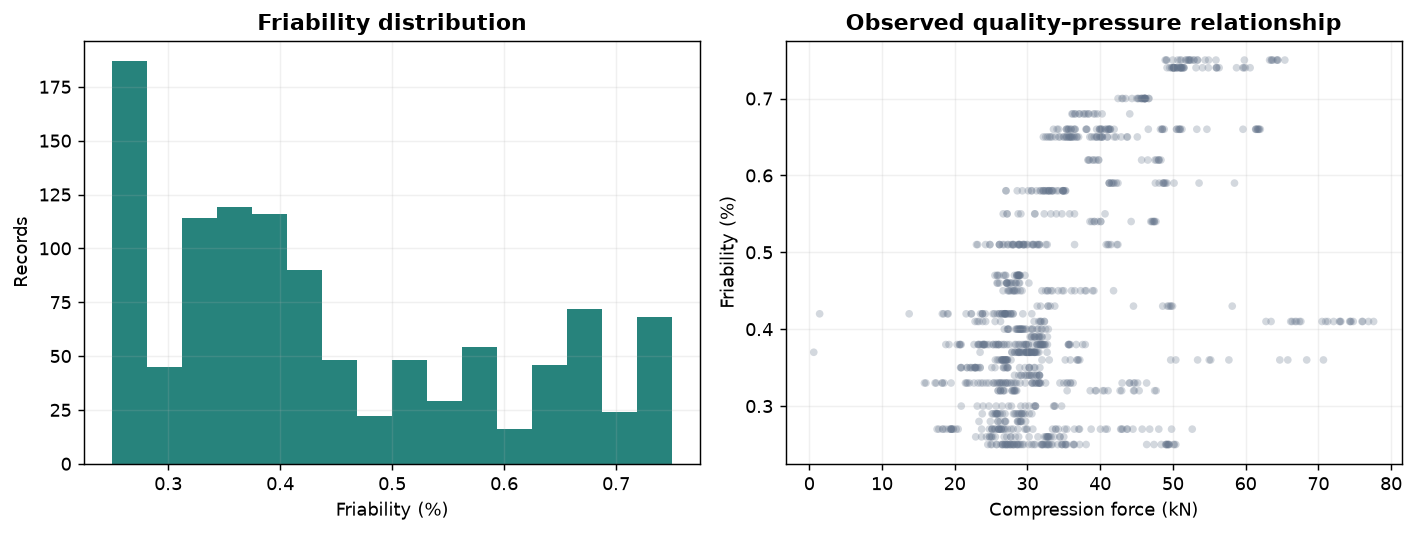

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].hist(data["friability_pct"], bins=16, color=TEAL, alpha=0.9)
axes[0].set(title="Friability distribution", xlabel="Friability (%)", ylabel="Records")

axes[1].scatter(
    data["compression_kn"],
    data["friability_pct"],
    s=18,
    alpha=0.28,
    color=SLATE,
    edgecolors="none",
)
axes[1].set(
    title="Observed quality–pressure relationship",
    xlabel="Compression force (kN)",
    ylabel="Friability (%)",
)

figure.tight_layout()
plt.show()

## 3. Model validation

An Extra Trees surrogate is used only to rank predictive signals and to illustrate generalization. The model is evaluated with five folds grouped by production lot. A random-row split is shown solely as a diagnostic comparison.

In [10]:
validation = evaluate_model_validation(data, random_state=SEED)

validation_summary = pd.DataFrame(
    {
        "Validation design": ["Grouped by lot", "Random rows"],
        "Mean R2": [
            validation.grouped_metrics["r2"].mean(),
            validation.random_row_metrics["r2"].mean(),
        ],
        "R2 standard deviation": [
            validation.grouped_metrics["r2"].std(ddof=0),
            validation.random_row_metrics["r2"].std(ddof=0),
        ],
        "Mean MAE (percentage points)": [
            validation.grouped_metrics["mae"].mean(),
            validation.random_row_metrics["mae"].mean(),
        ],
    }
)
display(validation_summary.round(4))

,Validation design,Mean R2,R2 standard deviation,Mean MAE (percentage points)
0,Grouped by lot,0.4431,0.1038,0.0869
1,Random rows,0.8461,0.0148,0.0420


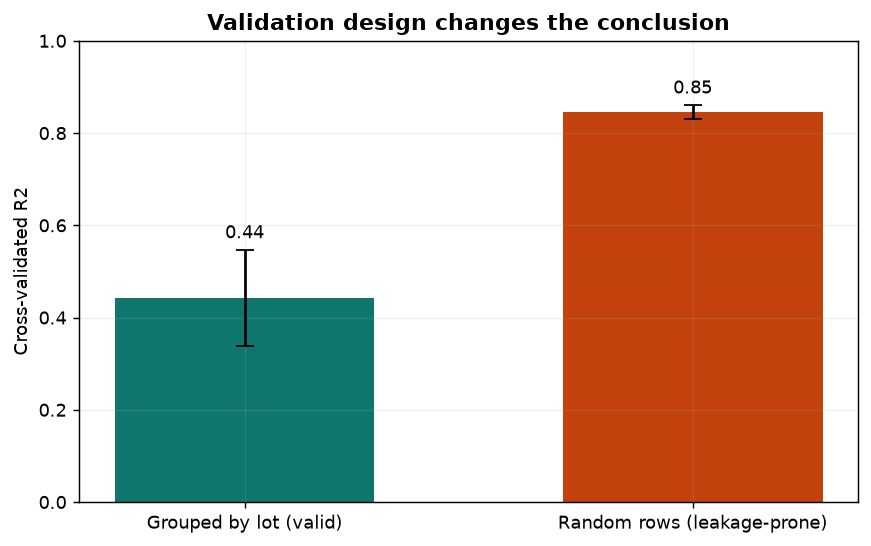

In [11]:
figure, axis = plt.subplots(figsize=(6.8, 4.3))
means = validation_summary["Mean R2"].to_numpy()
errors = validation_summary["R2 standard deviation"].to_numpy()
bars = axis.bar(
    ["Grouped by lot (valid)", "Random rows (leakage-prone)"],
    means,
    yerr=errors,
    color=[TEAL, CORAL],
    capsize=5,
    width=0.58,
)
axis.bar_label(bars, labels=[f"{value:.2f}" for value in means], padding=4)
axis.set(title="Validation design changes the conclusion", ylabel="Cross-validated R2", ylim=(0, 1))
figure.tight_layout()
plt.show()

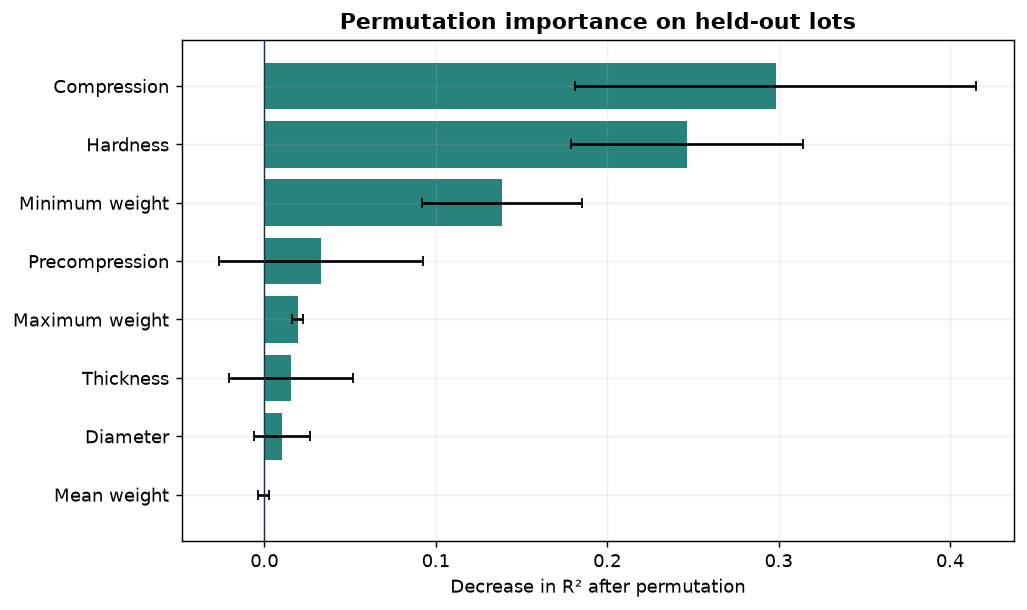

,label,importance_mean,importance_std
0,Compression,0.2983,0.1170
1,Hardness,0.2464,0.0678
2,Minimum weight,0.1387,0.0466
3,Precompression,0.0332,0.0594
4,Maximum weight,0.0195,0.0033


In [12]:
importance = validation.feature_importance.copy()
importance["label"] = importance["feature"].map(DISPLAY_NAMES)
plot_data = importance.sort_values("importance_mean")

figure, axis = plt.subplots(figsize=(8, 4.8))
axis.barh(
    plot_data["label"],
    plot_data["importance_mean"],
    xerr=plot_data["importance_std"],
    color=TEAL,
    alpha=0.9,
    capsize=3,
)
axis.axvline(0, color=NAVY, linewidth=0.8)
axis.set(title="Permutation importance on held-out lots", xlabel="Decrease in R² after permutation", ylabel="")
figure.tight_layout()
plt.show()

display(importance[["label", "importance_mean", "importance_std"]].head(5).round(4))

## 4. Multi-objective genetic optimization

We´ll use a true `ParetoFront`, not a scalar-style `HallOfFame`; the result is compared with an exhaustive Pareto calculation over all 1,098 candidates.

In [13]:
exact_front = exact_pareto_front(data)
front_columns = ["row_id", "lot_id", "friability_pct", "compression_kn"]
display(exact_front[front_columns].round(3))

,row_id,lot_id,friability_pct,compression_kn
0,946,1,0.25,24.55
1,628,40,0.26,22.89
2,67,30,0.27,17.58
3,651,6,0.33,15.84
4,230,20,0.37,0.62


In [14]:
ga_result = run_nsga2_search(data, seeds=(7, 19, 42))
coverage = pareto_coverage(ga_result.front, exact_front)

ga_summary = pd.DataFrame(
    {
        "Metric": [
            "Exact Pareto points",
            "NSGA-II Pareto points",
            "Pareto coverage",
            "Unique historical candidates evaluated",
            "Total fitness evaluations",
        ],
        "Value": [
            len(exact_front),
            len(ga_result.front),
            f"{coverage:.0%}",
            ga_result.unique_candidates_evaluated,
            ga_result.total_evaluations,
        ],
    }
)
display(ga_summary)

,Metric,Value
0,Exact Pareto points,5
1,NSGA-II Pareto points,5
2,Pareto coverage,100%
3,Unique historical candidates evaluated,1098
4,Total fitness evaluations,41403


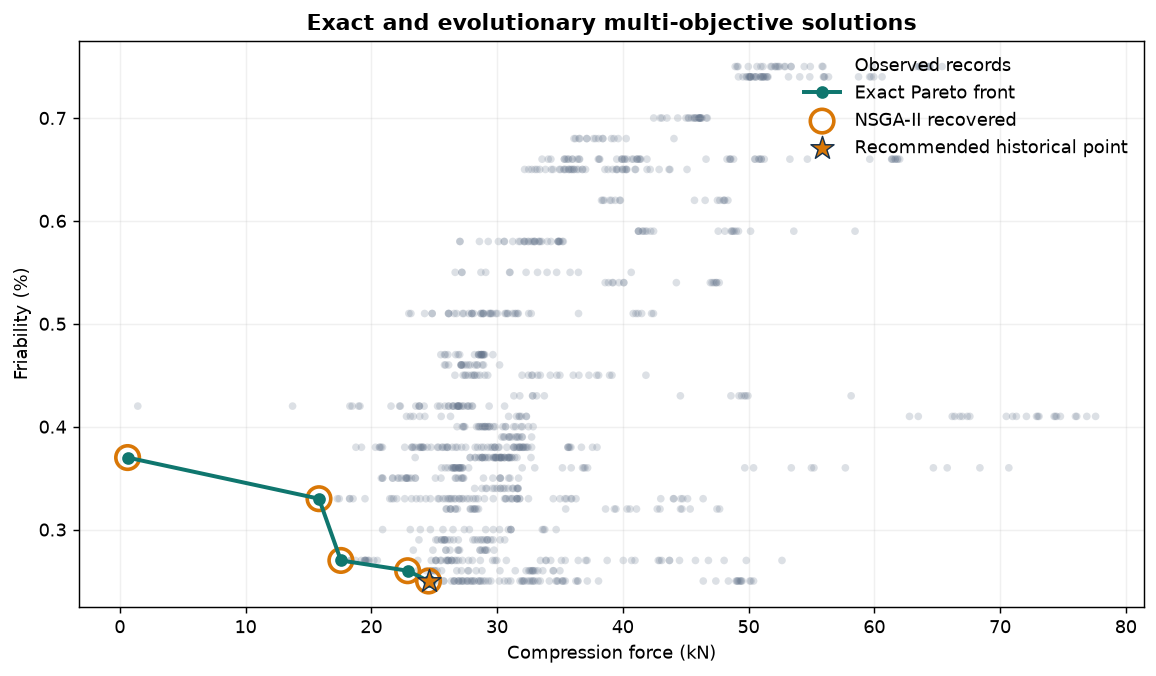

In [15]:
recommendation = exact_front.sort_values(["friability_pct", "compression_kn"]).iloc[0]
ordered_front = exact_front.sort_values("compression_kn")

figure, axis = plt.subplots(figsize=(9, 5.3))
axis.scatter(
    data["compression_kn"], data["friability_pct"],
    s=18, alpha=0.22, color=SLATE, edgecolors="none", label="Observed records"
)
axis.plot(
    ordered_front["compression_kn"], ordered_front["friability_pct"],
    marker="o", linewidth=2.2, color=TEAL, label="Exact Pareto front"
)
axis.scatter(
    ga_result.front["compression_kn"], ga_result.front["friability_pct"],
    s=170, facecolors="none", edgecolors=GOLD, linewidth=2,
    label="NSGA-II recovered"
)
axis.scatter(
    [recommendation["compression_kn"]], [recommendation["friability_pct"]],
    marker="*", s=180, color=GOLD, edgecolor=NAVY, linewidth=0.8,
    label="Recommended historical point", zorder=5
)
axis.set(
    title="Exact and evolutionary multi-objective solutions",
    xlabel="Compression force (kN)",
    ylabel="Friability (%)",
)
axis.legend(loc="upper right")
figure.tight_layout()
plt.show()

In [16]:
original_ga_pressure = 25.76
pressure_reduction_original = (
    original_ga_pressure - recommendation["compression_kn"]
) / original_ga_pressure * 100
pressure_reduction_median = (
    data["compression_kn"].median() - recommendation["compression_kn"]
) / data["compression_kn"].median() * 100

recommendation_table = pd.DataFrame(
    {
        "Metric": [
            "Historical row",
            "Production lot",
            "Friability",
            "Compression force",
            "Pressure reduction vs. original GA",
            "Pressure reduction vs. dataset median",
        ],
        "Value": [
            int(recommendation["row_id"]),
            int(recommendation["lot_id"]),
            f"{recommendation['friability_pct']:.2f}%",
            f"{recommendation['compression_kn']:.2f} kN",
            f"{pressure_reduction_original:.1f}%",
            f"{pressure_reduction_median:.1f}%",
        ],
    }
)
display(recommendation_table)

,Metric,Value
0,Historical row,946
1,Production lot,1
2,Friability,0.25%
3,Compression force,24.55 kN
4,Pressure reduction vs. original GA,4.7%
5,Pressure reduction vs. dataset median,21.5%


## 5. Interpretation

- **Compression, hardness, and minimum weight** are the strongest predictive signals on held-out lots.
- The corrected search identifies **five nondominated quality–pressure trade-offs**.
- The recommended historical profile maintains the minimum observed friability while reducing compression pressure relative to the initial genetic result.
- The `0.62 kN` Pareto point is retained mathematically but flagged by the data audit as a potential sensor or transcription anomaly; it should not become a production recommendation without verification.

## 6. Scientific foundation

We gratefully acknowledge **Julieta Villar Alvez**, author of *Factores que afectan a la compresión de comprimidos* (Universidad de Sevilla, 2017). Her experimental work was the principal pharmaceutical reference used to interpret pur results with the genetic algorithma, seeing the relationship among compression pressure, hardness, friability, formulation, humidity, and compression time.

The institutional record classifies the document as an **experimental Final Degree Project in Pharmacy**. It provides the domain rationale for the quality-pressure trade-off; the numerical recommendation in this work comes from the production dataset, exact Pareto calculation, and NSGA-II validation.

- [Official idUS record](https://idus.us.es/items/de5f0215-310f-4c95-b62e-fef0714b5a69)
- [Full document](https://idus.us.es/server/api/core/bitstreams/ff0722b4-1a38-47be-829d-ffdb4f5796d7/content)

## 7. Limitations and next steps

1. **Observational evidence:** feature importance is predictive, not causal.
2. **Lot-level target:** friability is measured once per lot and repeated across process rows.
3. **Production validation:** candidate settings require engineering review and a controlled confirmation batch.
4. **Future extension:** train a constrained surrogate model on additional experiments, then optimize continuous controllable settings with uncertainty penalties.